<a href="https://colab.research.google.com/github/enslern/The-AI-engineer-course-2026-Complete-AI-bootcamp/blob/main/langgraph_short_term_memory.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Short-Term Memory with the InMemorySaver Class

### Set the OpenAI API Key as an Environment Variable

In [1]:

!pip install langchain==0.3.25
!pip install langgraph==0.4.8
!pip install langchain-groq
!pip install langgraph-checkpoint-sqlite==0.3.17
!pip install grandalf==0.8

  Using cached langchain_core-0.3.86-py3-none-any.whl.metadata (3.2 kB)
Using cached langchain_core-0.3.86-py3-none-any.whl (461 kB)
  Attempting uninstall: langchain-core
    Found existing installation: langchain-core 1.6.10
    Uninstalling langchain-core-1.6.10:
      Successfully uninstalled langchain-core-1.6.10
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
langgraph-prebuilt 1.1.0 requires langchain-core>=1.3.1, but you have langchain-core 0.3.86 which is incompatible.
langgraph-sdk 0.4.5 requires langchain-core<2,>=1.4.0, but you have langchain-core 0.3.86 which is incompatible.
  Using cached langchain_core-1.6.10-py3-none-any.whl.metadata (4.8 kB)
Using cached langchain_core-1.6.10-py3-none-any.whl (573 kB)
  Attempting uninstall: langchain-core
    Found existing installation: langchain-core 0.3.86
    Uninstalling langchain-core-0.3.86:
      Succ

In [20]:
import os
import sys


sys.path.append(os.path.abspath("/content/drive/MyDrive/Colab Notebooks/resources"))

In [26]:
import os
import sys
import importlib.util

target_path = "/content/drive/MyDrive/Colab Notebooks/resources"
config_file_path = os.path.join(target_path, "config.py")

if os.path.exists(config_file_path):
    # Load the config module directly from its absolute file path
    spec = importlib.util.spec_from_file_location("config", config_file_path)
    config = importlib.util.module_from_spec(spec)
    sys.modules["config"] = config
    spec.loader.exec_module(config)

    # Set the environment variable
    os.environ["GROQ_API_KEY"] = config.GROQ_API_KEY
    print("[SUCCESS] Successfully imported config and set GROQ_API_KEY!")
else:
    print(f"[ERROR] Could not locate 'config.py' at {config_file_path}")

[SUCCESS] Successfully imported config and set GROQ_API_KEY!


### Import Relevant Classes and Functions

In [27]:
from langgraph.graph import START, END, StateGraph, MessagesState
from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage, AIMessage, SystemMessage, BaseMessage, RemoveMessage
from langgraph.checkpoint.memory import InMemorySaver

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Define the State

In [28]:
class State(MessagesState):
    summary: str

### Define the Nodes

In [29]:
chat=ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0,
    seed=365,
    max_tokens=100,
    reasoning_format="hidden",

)

/usr/local/lib/python3.13/dist-packages/pydantic/main.py:263: UserWarning: WARNING! seed is not default parameter.
                    seed was transferred to model_kwargs.
                    Please confirm that seed is what you intended.
  validated_self = self.__pydantic_validator__.validate_python(data, self_instance=self)


In [65]:
chat = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0,
    max_tokens=500
)


In [53]:
def ask_question(state: State) -> State:

    print(f"\n-------> ENTERING ask_question:")

    question = "What is your question?"
    print(question)

    return State(messages = [AIMessage(question), HumanMessage(input())])

In [66]:
def chatbot(state: State) -> State:

    print(f"\n-------> ENTERING chatbot:")

    system_message = f'''
    Here's a quick summary of what's been discussed so far:
    {state.get("summary", "")}

    Keep this in mind as you answer the next question.
    '''

    response = chat.invoke([SystemMessage(system_message)] + state["messages"])
    response.pretty_print()

    return State(messages = [response])

In [67]:
def summarize_messages(state: State) -> State:
    print(f"\n-------> ENTERING summarize_messages:")

    new_conversation = ""
    for i in state["messages"]:
        new_conversation += f"{i.type}: {i.content}\n\n"

    summary_instructions = f'''
Update the ongoing summary by incorporating the new lines of conversation below.
Build upon the previous summary rather than repeating it,
so that the result reflects the most recent context and developments.
Respond only with the summary.

Previous Summary:
{state.get("summary", "")}

New Conversation:
{new_conversation}
'''

    print(summary_instructions)

    summary = chat.invoke([HumanMessage(summary_instructions)])

    remove_messages = [RemoveMessage(id = i.id) for i in state["messages"][:]]

    return State(messages = remove_messages, summary = summary.content)

### Define the Graph

In [68]:
graph = StateGraph(State)

In [69]:
graph.add_node("ask_question", ask_question)
graph.add_node("chatbot", chatbot)
graph.add_node("summarize_messages", summarize_messages)

graph.add_edge(START, "ask_question")
graph.add_edge("ask_question", "chatbot")
graph.add_edge("chatbot", "summarize_messages")
graph.add_edge("summarize_messages", END)

In [70]:
checkpointer=InMemorySaver()
graph_compiled=graph.compile(checkpointer)

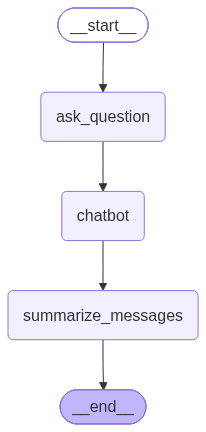

In [71]:
graph_compiled

In [76]:
config1={"configurable":{"thread_id":"1"}}
config2={"configurable":{"thread_id":"2"}}

In [77]:

graph_compiled.invoke(State(), config2)


-------> ENTERING ask_question:
What is your question?
where was he bron

-------> ENTERING chatbot:
================================== Ai Message ==================================

I’m happy to help, but I need a bit more information. Could you let me know who “he” is that you’re asking about? Once I know the person you’re referring to, I can tell you where they were born.

-------> ENTERING summarize_messages:

Update the ongoing summary by incorporating the new lines of conversation below. 
Build upon the previous summary rather than repeating it, 
so that the result reflects the most recent context and developments.
Respond only with the summary.

Previous Summary:


New Conversation:
ai: What is your question?

human: where was he bron

ai: I’m happy to help, but I need a bit more information. Could you let me know who “he” is that you’re asking about? Once I know the person you’re referring to, I can tell you where they were born.





{'messages': [],
 'summary': 'The user asked, “where was he bron,” seeking the birthplace of an unspecified male individual. The AI responded by asking for clarification, requesting the identity of “he” so it can provide the correct birth location.'}

##**the statesnap shot class**

In [80]:
graph_states=[i for i in graph_compiled.get_state_history(config1)]


In [79]:
graph_states

<generator object Pregel.get_state_history at 0x7bb0888ea140>

In [82]:
for i in graph_states[::-1]:
  print(f'''
  Messages:{i.values["messages"]}
  Summary:{i.values.get("summary","")}
  Next:{i.next}
  Step:{i.metadata["step"]}

  ''')


  Messages:[]
  Summary:
  Next:('__start__',)
  Step:-1
  
  

  Messages:[]
  Summary:
  Next:('ask_question',)
  Step:0
  
  

  Messages:[AIMessage(content='What is your question?', additional_kwargs={}, response_metadata={}, id='58a31910-27ef-4062-b243-f790094ece47', tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='who is the pm  of india', additional_kwargs={}, response_metadata={}, id='655ce45d-67c2-4982-9024-22cdeee45534')]
  Summary:
  Next:('chatbot',)
  Step:1
  
  

  Messages:[AIMessage(content='What is your question?', additional_kwargs={}, response_metadata={}, id='58a31910-27ef-4062-b243-f790094ece47', tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='who is the pm  of india', additional_kwargs={}, response_metadata={}, id='655ce45d-67c2-4982-9024-22cdeee45534'), AIMessage(content='As of the latest information available (up to June\u202f2024), the Prime Minister of India is **Narendra\u202fModi**. He has been in office since May\u202f2014, having